In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("Telco-Customer-Churn.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("\nColumn Names:")
print(df.columns.tolist())



Column Names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [5]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  70

In [6]:
print("\nStatistical Summary:")
display(df.describe(include="all").T)



Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("\nMissing Values:")
print(df.isnull().sum())




Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [8]:
print("\nDuplicate Records:", df.duplicated().sum())


Duplicate Records: 0


Handle inconsistent Values 

In [10]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

# Standardize Yes/No values
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].replace({
        "yes": "Yes",
        "no": "No",
        "YES": "Yes",
        "NO": "No"
    })

# Standardize gender values
if "gender" in df.columns:
    df["gender"] = df["gender"].str.title()

print("Inconsistent text values standardized.")
display(df.head())

Inconsistent text values standardized.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Convert columns to correct data types

In [11]:
for col in ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

print("Updated Data Types:")
print(df.dtypes)

Updated Data Types:
customerID          string[python]
gender              string[python]
SeniorCitizen                int64
Partner             string[python]
Dependents          string[python]
tenure                       int64
PhoneService        string[python]
MultipleLines       string[python]
InternetService     string[python]
OnlineSecurity      string[python]
OnlineBackup        string[python]
DeviceProtection    string[python]
TechSupport         string[python]
StreamingTV         string[python]
StreamingMovies     string[python]
Contract            string[python]
PaperlessBilling    string[python]
PaymentMethod       string[python]
MonthlyCharges             float64
TotalCharges               Float64
Churn               string[python]
dtype: object


handle missing values 

In [13]:
print("Missing Values Before Cleaning:")
print(df.isnull().sum())

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

# Fill missing numerical values with median
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values with mode
for col in df.select_dtypes(include=["object", "string", "category"]).columns:
    if df[col].isnull().any():
        mode_value = df[col].mode(dropna=True)
        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value.iloc[0])

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Missing Values Before Cleaning:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Missing Values After Cleaning:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0


Remove Duplicate Errrors

In [14]:
print("Duplicates Before:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates After:", df.duplicated().sum())
print("Updated Dataset Shape:", df.shape)

Duplicates Before: 0
Duplicates After: 0
Updated Dataset Shape: (7043, 21)


Detect and Handle outliers

In [15]:
outlier_columns = [
    col for col in ["tenure", "MonthlyCharges", "TotalCharges"]
    if col in df.columns
]

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col} - Outliers detected: {outliers}")

    df[col] = df[col].clip(lower=lower, upper=upper)

print("Outlier handling completed.")

tenure - Outliers detected: 0
MonthlyCharges - Outliers detected: 0
TotalCharges - Outliers detected: 0
Outlier handling completed.


Feature Engineering 

In [16]:
if "tenure" in df.columns:
    df["TenureGroup"] = pd.cut(
        df["tenure"],
        bins=[-1, 12, 24, 48, np.inf],
        labels=["0-12 Months", "13-24 Months",
                "25-48 Months", "49+ Months"]
    )

if "TotalCharges" in df.columns and "tenure" in df.columns:
    df["AverageMonthlySpend"] = (
        df["TotalCharges"] /
        df["tenure"].replace(0, np.nan)
    ).fillna(0)

print("New features created.")
display(df.head())

New features created.


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,AverageMonthlySpend
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 Months,29.85
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.5,No,25-48 Months,55.573529
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 Months,54.075
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 Months,40.905556
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 Months,75.825


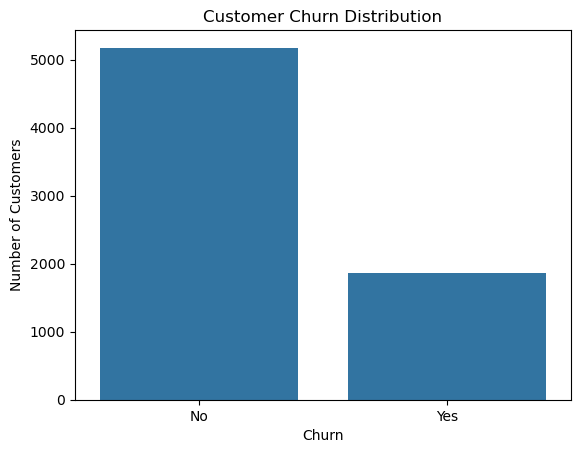

In [17]:
if "Churn" in df.columns:
    sns.countplot(data=df, x="Churn")
    plt.title("Customer Churn Distribution")
    plt.xlabel("Churn")
    plt.ylabel("Number of Customers")
    plt.show()

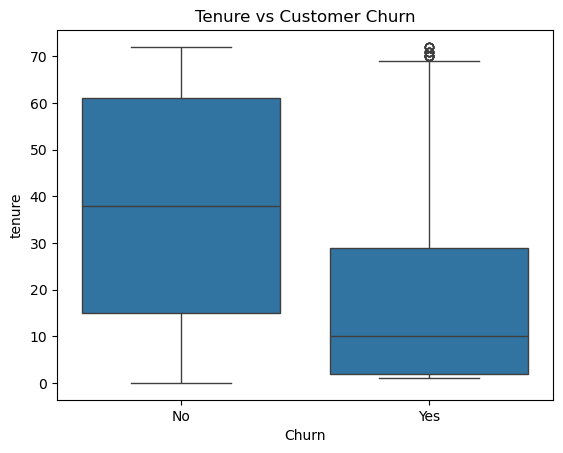

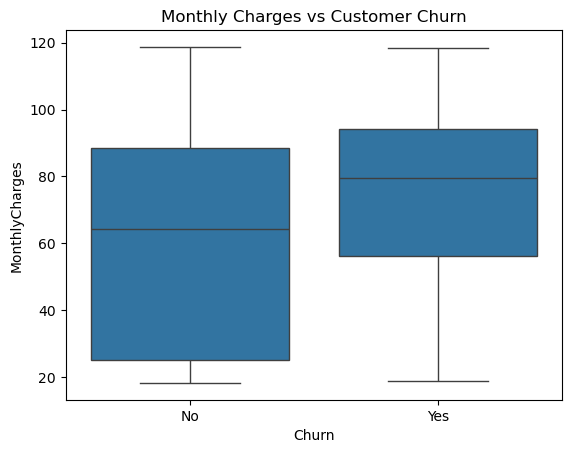

In [18]:
if "Churn" in df.columns and "tenure" in df.columns:
    sns.boxplot(data=df, x="Churn", y="tenure")
    plt.title("Tenure vs Customer Churn")
    plt.show()

if "Churn" in df.columns and "MonthlyCharges" in df.columns:
    sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
    plt.title("Monthly Charges vs Customer Churn")
    plt.show()

In [19]:
# Separate features and target
y = df["Churn"].astype(str).str.strip().str.title()

X = df.drop(columns=["Churn"])

# Remove customer ID if present
id_cols = [
    col for col in X.columns
    if col.lower().replace("_", "") == "customerid"
]
X = X.drop(columns=id_cols)

# Convert categorical features to numeric
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Normalize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Data splitting and scaling completed.")

Training Data: (5634, 34)
Testing Data: (1409, 34)
Data splitting and scaling completed.


In [20]:
df.to_csv("cleaned_telecom_churn.csv", index=False)

prepared_df = X.copy()
prepared_df["Churn"] = y.values

prepared_df.to_csv("prepared_telecom_churn.csv", index=False)

print("Cleaned dataset saved successfully!")
print("File: cleaned_telecom_churn.csv")
print("Prepared dataset saved successfully!")
print("File: prepared_telecom_churn.csv")

Cleaned dataset saved successfully!
File: cleaned_telecom_churn.csv
Prepared dataset saved successfully!
File: prepared_telecom_churn.csv


In [21]:
print("FINAL DATASET SUMMARY")
print("---------------------")
print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])
print("Duplicate Records:", df.duplicated().sum())
print("Missing Values:", df.isnull().sum().sum())

print("\nChurn Distribution:")
print(df["Churn"].value_counts())

display(df.head())

FINAL DATASET SUMMARY
---------------------
Total Records: 7043
Total Columns: 23
Duplicate Records: 0
Missing Values: 0

Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: Int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,AverageMonthlySpend
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0-12 Months,29.85
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.5,No,25-48 Months,55.573529
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,0-12 Months,54.075
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,25-48 Months,40.905556
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,0-12 Months,75.825
